# Battery flexibility trading: a controller's toolkit
**Interval reconciliation · variance bridge · rolling forecast and scenarios · product profitability, built on real German day-ahead prices**

A battery optimizer trades storage assets in 15-minute intervals across several markets. The controlling questions are always the same:
*do our MWh and euros agree with the exchange, interval by interval? Why did we miss the forecast? What happens in a bad year? Which product actually earns money?*
This notebook answers each of them end to end, from the raw data pull to an Excel model with built-in checks.

The forecasting part builds on my earlier short-term forecasting work (ISPR 2022, published in *Towards Industry 5.0*, Springer): walk-forward evaluation against naive benchmarks, and judging a forecast by the decision it drives, not only by its error metric.

**Results at a glance** (details in each section)
| Area | Result |
|---|---|
| Data audit | 273,500 price intervals since 2019, all 15 DST days complete; a widely used alternative file was rejected after testing (no negative prices, two series mixed) |
| Forecast | Walk-forward gradient boosting: MAE 24.2 vs 29.6 EUR/MWh for the naive benchmark; worth about 2.2-2.9k EUR per MW and year in captured spread |
| Reconciliation | 23,274 intervals / 16.6M EUR over 12 months; 99.3 % within tolerance; every injected break type found, plus a systematic truncation and a 0.3 % meter bias that no single interval reveals |
| Variance | Exact price-volume-mix bridge; one-month-ahead errors are 62 % market spread; the flat reserve-price assumption is biased in 16 of 21 months |
| Scenarios | 12-month net trading revenue: stress 2.9M / base 8.0M / upside 10.5M EUR; revenues are right-skewed, so the normal approximation overstates downside risk |
| Profitability | Intraday looks loss-making under one allocation key and profitable under the other; dropping it would cut company result by 153k EUR (death spiral test) |

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore", category=FutureWarning)

def find_root() -> Path:
    cands = [Path.cwd(), Path.cwd().parent]
    if Path("/kaggle/input").exists():
        cands += [p for pat in ("*", "*/*", "*/*/*", "*/*/*/*") for p in Path("/kaggle/input").glob(pat) if p.is_dir()]
    for c in cands:
        if (c / "src" / "fcc").exists():
            return c
    raise FileNotFoundError("project root with src/fcc not found")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
OUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else ROOT / "outputs"
CACHE = OUT / "cache"
OUT.mkdir(parents=True, exist_ok=True)

from fcc import (config, market, forecast, dispatch, portfolio, synth, recon, variance, scenarios,
                 profitability, excel_out, viz)
from fcc.config import ASSETS, TZ
viz.style()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
eur = lambda v: f"{v:,.0f} EUR"
print("root:", ROOT.name, "| outputs:", OUT.relative_to(ROOT) if OUT.is_relative_to(ROOT) else OUT)

root: flex_controlling_case | outputs: outputs


## 0 · Scope: what is real and what is synthetic

| Element | Status | Source |
|---|---|---|
| DE-LU day-ahead prices (hourly until 30 Sep 2025, 15-minute after), load, residual load, wind, solar | **real** | Energy-Charts API (Fraunhofer ISE), data from Bundesnetzagentur / SMARD, CC BY 4.0 |
| Battery dispatch (perfect foresight and forecast-based) | **computed** from real prices | linear programme per local delivery day |
| Assets, contracts, ledger, exchange statements, schedules (Fahrplan), meters | **synthetic** | generated here, with injected breaks and a ground-truth log |
| Reserve capacity prices, intraday value, imbalance price (reBAP) | **modelled** | parameters in the assumptions table |

Nothing here describes a real company. Every parameter is declared once, with a provenance label (`observed data`, `domain primer`, `illustrative assumption`), and the table below is also written to the Excel `Inputs` sheet. **Non-goals:** accounting treatment, tax, project finance, margining.

The economics have two layers. **Layer 1** is what the *assets* earn in the markets; this is the base of every analysis here. **Layer 2** is what the *optimizer company* keeps (e.g. a revenue share). Layer 2 depends entirely on contract terms, so it is a separate, optional module (`contracts.py`) with illustrative terms. It is used only where a company view is unavoidable: company EBITDA in the scenarios and the product P&L.

In [2]:
A = config.assumptions_table()
print(A["source"].value_counts().to_string())
display(A[["parameter", "value", "unit", "source", "note"]])

source
illustrative assumption    51
domain primer               9
observed data               2


,parameter,value,unit,source,note
0,timezone,Europe/Berlin,tz,domain primer,"all maths in UTC, local time only for reporting"
1,interval_hours,0.25,h,domain primer,15-minute market time unit (MTU)
2,da_15min_start_utc,2025-09-30 22:00,UTC,observed data,day-ahead moved from hourly to 15-minute products on 1 Oct 2025 (l...
3,round_trip_efficiency,0.88,share,domain primer,Li-ion typically 85-90 %
4,cell_replacement_value,"90,000.00",EUR/MWh capacity,illustrative assumption,
...,...,...,...,...,...
57,random_seed,42,seed,illustrative assumption,
58,history_start,2019-01-01,date,observed data,market history used for statistics
59,backtest_start,2024-01-01,date,illustrative assumption,forecast / dispatch evaluation window
60,recon_start,2025-10-01,date,illustrative assumption,reconciliation window = 12 months of native 15-min DA


## 1 · Data: pull, clean, and test before trusting

Prices and fundamentals are pulled with `src/fetch_data.py` (Energy-Charts API, yearly / quarterly chunks, cached and resumable because the API rate-limits). All arithmetic runs in **UTC**. Local time is used only for reporting, because a German delivery day has 92, 96 or 100 quarter-hours. The first checks are therefore structural: completeness per local day, duplicates, the DST days, and the switch from hourly to 15-minute day-ahead products.

In [3]:
price_df = market.load_price(ROOT / "data/energy_charts/price_de_lu.parquet")
P = price_df["price_eur_mwh"]
F = market.load_fundamentals(ROOT / "data/energy_charts/fundamentals_de.parquet")
LAST_DAY = P.index.max().tz_convert(TZ).strftime("%Y-%m-%d")
audit = market.audit_price(price_df, "2019-01-01", LAST_DAY)
display(pd.Series(audit, name="value").to_frame())
display(market.annual_stats(price_df).loc[2019:])
ic = market.interval_count_check(P.index, "2019-01-01", LAST_DAY)
print("DST days (only these may differ from 96 intervals):")
display(ic[ic["n_expected"] != 96][["n_expected", "n_found", "gap"]])
print("native resolution:", price_df["native_res_min"].value_counts().to_dict(),
      "| first 15-minute day-ahead interval:", P.index[price_df["native_res_min"] == 15].min())

,value
intervals,273500
first_utc,2018-12-31 23:00:00+00:00
last_utc,2026-10-19 21:45:00+00:00
duplicated_timestamps,0
missing_prices,0
local_days_checked,2849
dst_days,15
dst_days_complete,15
regular_days_with_gap,0
negative_price_intervals,10053


,mean,std,min,max,negative_hours
year,,,,,
2019,37.67,15.52,-90.01,121.46,211.00
2020,30.47,17.50,-83.94,200.04,298.00
2021,96.85,73.68,-69.00,620.00,139.00
2022,235.45,142.80,-19.04,871.00,69.00
2023,95.18,47.58,-500.00,524.27,301.00
2024,78.51,52.72,-135.45,936.28,457.00
2025,89.32,52.48,-250.32,583.40,574.75
2026,111.53,68.87,-499.99,747.10,463.50


DST days (only these may differ from 96 intervals):


,n_expected,n_found,gap
local_date,,,
2019-03-31,92,92,0
2019-10-27,100,100,0
2020-03-29,92,92,0
2020-10-25,100,100,0
2021-03-28,92,92,0
2021-10-31,100,100,0
2022-03-27,92,92,0
2022-10-30,100,100,0
2023-03-26,92,92,0


native resolution: {60: 236636, 15: 36864} | first 15-minute day-ahead interval: 2025-09-30 22:00:00+00:00


### 1.1 Deep dive: the more popular file that does not add up
Before settling on a source I tested a widely shared Hugging Face dataset that is described as "DE-LU day-ahead prices, 15-minute resolution". I checked it against the reference series year by year instead of trusting its README.

In [4]:
hf = market.audit_secondary_source(ROOT / "data/raw/entsoe_delu_dayahead_prices.parquet", price_df)
display(hf)

,reference mean,file mean (all rows),rows per distinct timestamp,reference negative hours,file negative rows,reference min,file min,file max,reference max
year,,,,,,,,,
2019,37.67,39.03,1.26,211.00,0,-90.01,0.00,121.81,121.46
2020,30.47,32.64,1.25,298.00,0,-83.94,0.00,325.10,200.04
2021,96.85,100.92,1.26,139.00,0,-69.00,0.00,"2,985.76",620.00
2022,235.44,241.83,1.26,70.00,0,-19.04,0.00,"2,999.99",871.00
2023,95.18,101.93,1.26,300.00,0,-500.00,0.00,800.00,524.27
2024,78.51,83.76,1.25,457.00,0,-135.45,0.00,"1,398.02",936.28
2025,89.33,96.99,1.45,574.75,0,-250.32,0.00,834.60,583.40


**Finding.** That file is not a day-ahead price series:
- **Two series mixed.** There are 1.25-1.45 rows per timestamp.
- **No negative prices.** It has not a single negative price before 2026, although Germany had 70-575 negative hours per year.
- **Impossible maxima.** It peaks at 2,999.99 EUR/MWh where the day-ahead maximum was 871.
- **Inflated means.** Annual means are 3-9 % too high.

Any battery-revenue analysis built on it would overstate spreads and miss every negative-price charging opportunity. This is the kind of check the role asks for: *question the numbers, not just run them*.

## 2 · Short-term price forecast and what it is worth

**Information discipline.** The day-ahead auction for day D closes at 12:00 on D-1. The forecast may therefore use:
- day-ahead prices up to D-1 (published on D-2);
- actual load, wind and solar only up to D-2, because D-1 actuals are incomplete at forecast time.

**Models.** A weekday-aware naive benchmark (D-1 on Tue-Fri, D-7 otherwise) and a gradient-boosting model. The model is re-fitted every quarter on all earlier data and predicts the next quarter strictly out of sample (2024-01 to 2026-10).

In [5]:
t0 = time.time()
feat = forecast.build_features(P, F)
ml_path = CACHE / "ml_forecast.parquet"
if ml_path.exists():
    ml = pd.read_parquet(ml_path)["ml"]
else:
    ml = forecast.walk_forward(feat, config.BACKTEST_START, LAST_DAY, step_months=3)
    CACHE.mkdir(parents=True, exist_ok=True); ml.to_frame().to_parquet(ml_path)
print(f"walk-forward forecast: {len(ml):,} intervals, {time.time() - t0:.0f}s")
y = feat.loc[ml.index, "price"]
fm = pd.DataFrame({
    "naive (D-1 / D-7 weekday rule)": forecast.metrics(y, feat.loc[ml.index, "naive"]),
    "naive D-1": forecast.metrics(y, feat.loc[ml.index, "lag_24h"]),
    "gradient boosting (walk-forward)": forecast.metrics(y, ml),
}).T
display(fm.round(2))
yr = ml.index.tz_convert(TZ).year
by_year = pd.DataFrame({f"{k} {v}": [forecast.metrics(y[yr == yy], (ml if k == "ML" else feat.loc[ml.index, "naive"])[yr == yy])[v]
                                    for yy in sorted(set(yr))] for k in ["ML", "naive"] for v in ["MAE", "bias (mean error)"]},
                       index=sorted(set(yr)))
display(by_year.round(2))

walk-forward forecast: 98,204 intervals, 3s


,MAE,RMSE,WAPE %,bias (mean error),MAPE % (|y|>=5),MAPE % (all),n
naive (D-1 / D-7 weekday rule),29.59,46.96,31.70,0.36,50.53,"4,290.99","98,204.00"
naive D-1,28.44,45.18,30.46,-0.19,47.19,"4,124.98","98,204.00"
gradient boosting (walk-forward),24.18,37.37,25.90,1.71,41.45,"4,408.67","98,204.00"


,ML MAE,ML bias (mean error),naive MAE,naive bias (mean error)
2024,22.95,3.57,27.91,-0.74
2025,22.51,1.31,27.62,0.97
2026,27.82,-0.10,34.16,0.98


**Reading the metrics.**
- **Error.** The model cuts MAE from 29.6 to 24.2 EUR/MWh (-18 %), and WAPE from 31.7 % to 25.9 %.
- **Bias.** Bias stays small (+1.7 EUR/MWh), so the error is mostly noise rather than a systematic offset.
- **MAPE.** Plain MAPE is useless here (about 4,400 %): prices near zero or negative blow it up. Error metrics for power prices should be WAPE / MAE plus bias, never MAPE alone.

dispatch (perfect foresight 2019+, forecast-based 2024-01-01+): 0s


Day-ahead arbitrage, 2-hour battery, net EUR per MW (fees and degradation included); 2026 = Jan-Oct


,perfect foresight,ML forecast,naive forecast,capture ML %,capture naive %,"ML uplift vs naive, EUR/MW"
ts_utc,,,,,,
2024,"59,436.90","50,681.10","48,482.50",85.30,81.60,"2,198.60"
2025,"70,710.00","60,757.30","57,867.60",85.90,81.80,"2,889.80"
2026,"78,910.20","69,181.50","66,986.70",87.70,84.90,"2,194.90"


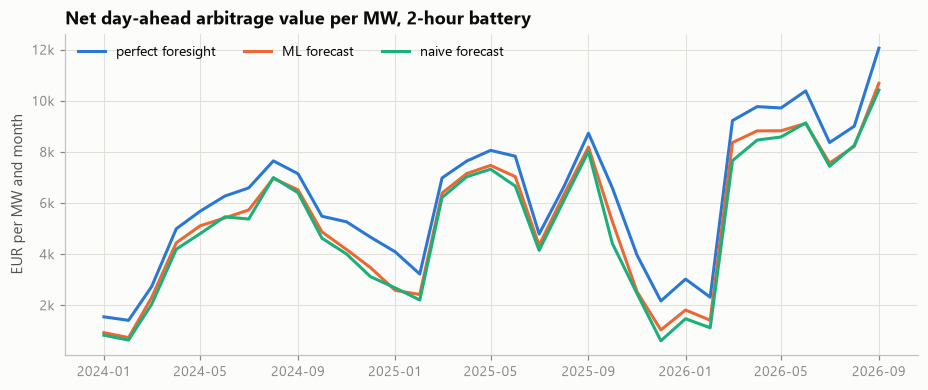

In [6]:
t0 = time.time()
sets = portfolio.dispatch_sets(P, ml, CACHE, config.BACKTEST_START)
naive_px = feat.loc[ml.index, "naive"].fillna(ml)
naive_sched = portfolio.cached(CACHE / "sched_naive_d2_cap1.parquet", lambda: dispatch.run_dispatch(naive_px, 2.0, 1.0))
print(f"dispatch (perfect foresight 2019+, forecast-based {config.BACKTEST_START}+): {time.time() - t0:.0f}s")

ref = sets[(2.0, 1.0)]
idx = ml.index
val = {name: dispatch.settle(s.reindex(idx), P.reindex(idx)) for name, s in
       [("perfect foresight", ref["pf"]), ("ML forecast", ref["fc"]), ("naive forecast", naive_sched)]}
yr = idx.tz_convert(TZ).year
cap = pd.DataFrame({n: v["net_eur"].groupby(yr).sum() for n, v in val.items()})
cap["capture ML %"] = 100 * cap["ML forecast"] / cap["perfect foresight"]
cap["capture naive %"] = 100 * cap["naive forecast"] / cap["perfect foresight"]
cap["ML uplift vs naive, EUR/MW"] = cap["ML forecast"] - cap["naive forecast"]
print("Day-ahead arbitrage, 2-hour battery, net EUR per MW (fees and degradation included); 2026 = Jan-Oct")
display(cap.round(1))
mon = pd.DataFrame({n: dispatch.monthly(v)["net_eur"] for n, v in val.items()})
mon = mon[mon.index <= "2026-09-01"]                      # complete months only (October 2026 is partial)
ax = viz.lines(mon, list(mon.columns), "Net day-ahead arbitrage value per MW, 2-hour battery", "EUR per MW and month", scale="k")
plt.show()

**From error to euros.** The same battery (2 h, fees and degradation in the objective) is dispatched three ways:
- with perfect foresight (the theoretical maximum);
- with the ML forecast;
- with the naive forecast.

The **capture rate** (realised / theoretical) is 85-88 % for the ML forecast vs 82-85 % for naive, about **2.2-2.9k EUR per MW and year**. For a 100 MW portfolio that is roughly 0.2-0.3M EUR a year, which is the number a forecast improvement should be judged by.

## 3 · The portfolio (Layer 1)

Three operating assets with different economics, plus one contracted asset that is not built yet (pre-COD, only used in the forward view):
- **BESS-A:** 60 MW / 2 h, stand-alone, 30 % of power in reserve markets.
- **BESS-B:** 30 MW / 2 h, co-located with PV. Discharge is capped in PV hours.
- **BESS-C:** 10 MW / 1 h. Planned COD March 2025, actual June 2025.
- **BESS-D:** 20 MW, planned COD March 2027.

Revenue lines per asset and month:
- day-ahead arbitrage (from the forecast-based dispatch);
- intraday value (modelled);
- reserve capacity (modelled price path that falls as storage saturates the market);
- minus exchange fees, degradation, and imbalance cost (modelled reBAP).

,asset_id,kind,mw,duration_h,cod_plan,cod_actual,customer,reserve_share,grid_cap_frac,contract
0,BESS-A,stand-alone,60.00,2.00,2024-01-01,2024-01-01,C1,0.30,1.00,net_fixed
1,BESS-B,co-located,30.00,2.00,2024-07-01,2024-07-01,C2,0.20,0.40,tiered_floor
2,BESS-C,stand-alone,10.00,1.00,2025-03-01,2025-06-01,C3,0.00,1.00,fixed_min_fee
3,BESS-D,stand-alone,20.00,2.00,2027-03-01,,C4,0.25,1.00,net_fixed


Layer 1 - asset net trading revenue by year (EUR); 2026 = Jan-Sep


,gross_da,id_rev,res_rev,fees,deg,imb_cost,net_rev,MW (avg),EUR/MW/yr
year,,,,,,,,,
2024,"3,490,870.00","822,666.00","1,318,053.00","18,186.00","589,326.00","47,749.00","4,976,327.00",75.00,"66,351.00"
2025,"4,976,989.00","1,187,015.00","1,337,894.00","23,556.00","763,345.00","225,850.00","6,489,147.00",96.00,"67,713.00"
2026,"5,222,303.00","1,252,922.00","698,454.00","19,511.00","583,238.00","136,826.00","6,434,105.00",100.00,"85,788.00"


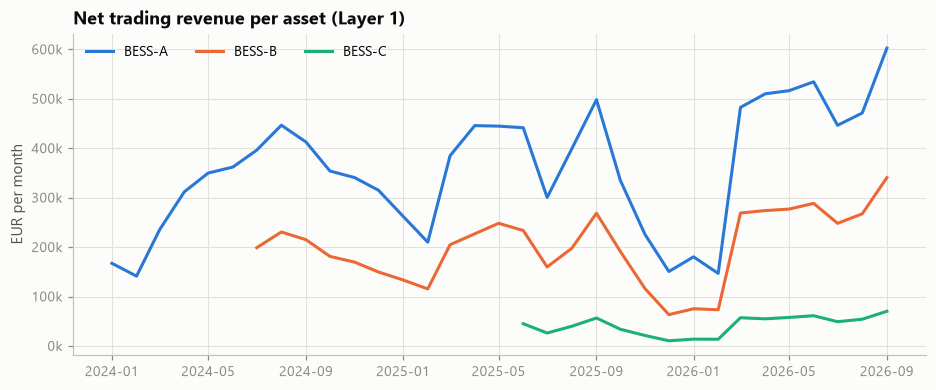

In [7]:
display(pd.DataFrame([vars(a) for a in ASSETS]))
reb = portfolio.full_rebap(P)
pm = portfolio.portfolio_monthly(sets, P, reb, config.BACKTEST_START, "2026-09-30")
yr_tab = pm.assign(year=pm["month"].dt.year).groupby("year")[
    ["gross_da", "id_rev", "res_rev", "fees", "deg", "imb_cost", "net_rev"]].sum()
yr_tab["MW (avg)"] = pm.assign(year=pm["month"].dt.year).groupby(["year", "month"])["mw"].sum().groupby("year").mean()
yr_tab["EUR/MW/yr"] = yr_tab["net_rev"] / yr_tab["MW (avg)"] / pm.assign(year=pm["month"].dt.year).groupby("year")["month"].nunique() * 12
print("Layer 1 - asset net trading revenue by year (EUR); 2026 = Jan-Sep")
display(yr_tab.round(0))
wide = pm.pivot_table(index="month", columns="asset_id", values="net_rev", aggfunc="sum")
viz.lines(wide, list(wide.columns), "Net trading revenue per asset (Layer 1)", "EUR per month", scale="k")
plt.show()

Net trading revenue is about 66k EUR/MW/yr in 2024-25 and 86k annualised in 2026, driven by wider day-ahead spreads (average price 112 vs 89 EUR/MWh in 2025). Reserve revenue moves the other way: 1.34M EUR in 2025, 0.70M in the first nine months of 2026. That is the saturation effect, and it comes back in the variance and scenario sections.

## 4 · Interval-by-interval reconciliation (the core)

Every 15-minute interval exists in up to four records:

| Record | Owner | Format here |
|---|---|---|
| Trading ledger | internal (the "CSV from Data Science") | UTC timestamp, net MWh (sell +), price, amount |
| Exchange / CCP settlement statement | exchange / clearing house | **local clock time**, separate buy / sell columns, A/B marker for the repeated hour |
| Schedule notified to the TSO (Fahrplan) | optimizer / BRP | UTC, MWh |
| Meter | asset | UTC, MWh |

Window: the first 12 months of native 15-minute day-ahead products (Oct 2025 to Sep 2026), three assets. Breaks were injected on purpose, with a ground-truth log, so the engine can be *scored* rather than just demonstrated. Sample CSVs for one month are written to `outputs/raw_csv_sample/`.

In [8]:
fc_by_variant = {k: v["fc"] for k, v in sets.items()}
ops = synth.build_ops(P, fc_by_variant, config.RECON_START, config.RECON_END, seed=config.RANDOM_SEED)
print({k: f"{len(getattr(ops, k)):,} rows" for k in ["ledger", "ecc", "fahrplan", "meter"]})
raw_dir = OUT / "raw_csv_sample"; raw_dir.mkdir(exist_ok=True)
m = ops.ledger["ts_utc"].dt.tz_convert(TZ).dt.strftime("%Y-%m") == "2025-10"
ops.ledger[m].to_csv(raw_dir / "ledger_2025-10.csv", index=False)
ops.ecc[ops.ecc["delivery_date"].str.startswith("2025-10")].to_csv(raw_dir / "ecc_statement_2025-10.csv", index=False)
print("Trading ledger (internal export, UTC, net MWh: sell +):")
display(ops.ledger.head(4))
print("Exchange / CCP statement (as delivered: local clock time, buy and sell columns, A/B marker for the repeated hour):")
display(ops.ecc[ops.ecc["delivery_date"] == "2025-10-26"].iloc[6:12])

{'ledger': '23,268 rows', 'ecc': '23,262 rows', 'fahrplan': '23,250 rows', 'meter': '105,120 rows'}
Trading ledger (internal export, UTC, net MWh: sell +):


,ts_utc,asset_id,net_mwh,price_eur_mwh,amount_eur
0,2025-09-30 23:45:00+00:00,BESS-A,-8.87,84.09,-745.49
1,2025-10-01 05:00:00+00:00,BESS-A,10.50,160.95,"1,689.97"
2,2025-10-01 05:15:00+00:00,BESS-A,10.50,181.48,"1,905.54"
3,2025-10-01 05:30:00+00:00,BESS-A,10.50,180.23,"1,892.41"


Exchange / CCP statement (as delivered: local clock time, buy and sell columns, A/B marker for the repeated hour):


,asset_id,delivery_date,time_local,dst_flag,sell_mwh,buy_mwh,clearing_price,amount_eur,fee_eur
698,BESS-A,2025-10-26,11:45,,0.00,10.50,-0.08,0.84,1.05
699,BESS-A,2025-10-26,12:00,,0.00,10.50,-0.08,0.84,1.05
700,BESS-A,2025-10-26,12:15,,0.00,10.50,-0.07,0.74,1.05
701,BESS-A,2025-10-26,12:30,,0.00,10.50,-0.05,0.52,1.05
702,BESS-A,2025-10-26,12:45,,0.00,10.50,-0.06,0.63,1.05
703,BESS-A,2025-10-26,13:00,,0.00,10.50,-0.06,0.63,1.05


### 4.1 Time first
Statements speak local time; on 26 Oct 2025 the hour 02:00-03:00 happens twice. The engine converts every row to UTC, using the A/B marker or, where an export lost it, the row sequence (and reports that it had to). For comparison, the classic shortcut of joining on local clock time breaks: it produces keys with several matches and rows that find no partner.

In [9]:
ep, notes = recon.parse_ecc(ops.ecc)
print("parsing notes:", notes)
print("naive join on local clock time:", recon.naive_local_join_stats(ops.ledger, ops.ecc))

parsing notes:

 {'ambiguous_rows': 3, 'ambiguous_without_marker': 1, 'nonexistent_local_times': 0}
naive join on local clock time: {'rows_joined': 23286, 'keys_with_fan_out (>1 match)': 12, 'one_sided_rows': 30}


### 4.2 Two-way match: ledger vs exchange statement
Each interval is compared on volume, price and amount. Differences inside a written tolerance (0.005 MWh; amount tolerance scaled by price) clear automatically. Anything else gets a signature-based classification:

| Signature | Classification |
|---|---|
| Interval on one side only | missing in statement / ledger |
| Row more than once | duplicate |
| Volume ratio 0.25 or 4 | **MW vs MWh** (a 15-minute interval is a factor of 4) |
| Ratio -1 | buy / sell **sign convention** |
| Same volume, different price | price correction |
| Otherwise | partial fill / volume difference |

Small differences that *always point the same way* are tested per asset and month. Individually harmless, collectively a systematic error.

In [10]:
rec = recon.reconcile_two_way(ops.ledger, ep)
summ = recon.summary(rec)
display(pd.Series(summ, name="value").to_frame())
display(rec["status"].value_counts().to_frame("intervals"))
reg2 = recon.break_register(rec)
print("Break register (two-way), largest first:")
display(reg2[["break_id", "asset_id", "local_date", "type", "n_intervals", "mwh_diff", "eur_impact", "severity", "owner",
              "root_cause", "age_days"]].head(14))
print("Systematic small differences (one-sided):")
display(rec.attrs["systematic"])

,value
intervals_compared,"23,274.00"
gross_volume_mwh,"148,406.23"
gross_amount_eur,"16,641,813.73"
within_tolerance_%,99.33
of which part of a systematic finding,"1,327.00"
intervals outside tolerance (breaks),156.00
net_diff_eur,"-13,898.59"
abs_diff_eur,"153,420.41"


,intervals
status,
CLEAR,21791
ROUNDING_BIAS,1327
UNIT_X4,56
MISSING_IN_ECC,24
VOLUME_DIFF,24
PRICE_DIFF,18
SIGN_FLIP,16
DUPLICATE_ECC,12
MISSING_IN_LEDGER,6


Break register (two-way), largest first:


,break_id,asset_id,local_date,type,n_intervals,mwh_diff,eur_impact,severity,owner,root_cause,age_days
0,BRK-0001,BESS-A,2026-05-07,MISSING_IN_ECC,8,84.00,"8,553.09",high,exchange ops / data feed,ECC statement incomplete or late,146
1,BRK-0002,BESS-A,2026-01-17,MISSING_IN_ECC,8,-44.53,"-6,884.44",high,exchange ops / data feed,ECC statement incomplete or late,255
2,BRK-0003,BESS-B,2025-10-31,UNIT_X4,28,29.45,"-6,110.26",high,data science export,MW vs MWh confusion (15 min = factor 4),333
3,BRK-0004,BESS-C,2026-09-29,SIGN_FLIP,16,4.09,"-3,795.57",high,exchange ops / data feed,buy / sell convention reversed,1
4,BRK-0005,BESS-B,2026-02-06,UNIT_X4,28,29.45,"-2,706.79",high,data science export,MW vs MWh confusion (15 min = factor 4),235
5,BRK-0006,BESS-B,2025-12-06,MISSING_IN_LEDGER,6,-19.58,"-1,293.49",medium,data science export,trades absent from ledger export,297
6,BRK-0007,BESS-A,2026-02-13,DUPLICATE_ECC,12,-26.54,-704.47,medium,exchange ops / data feed,statement rows delivered twice,228
7,BRK-0008,BESS-A,2026-05-14,MISSING_IN_ECC,8,84.00,503.37,medium,exchange ops / data feed,ECC statement incomplete or late,139
8,BRK-0009,BESS-C,2026-05-10,VOLUME_DIFF,8,1.22,-421.42,medium,trading desk,partial fill / cancellation not reflected in ledger,143
9,BRK-0010,BESS-C,2025-11-24,VOLUME_DIFF,8,0.09,-373.36,medium,trading desk,partial fill / cancellation not reflected in ledger,309


Systematic small differences (one-sided):


,asset_id,local_month,n_small_diffs,one_sided_share,net_mag_diff_mwh
0,BESS-A,2025-10,127,1.00,-0.05
1,BESS-A,2025-11,119,1.00,-0.05
2,BESS-A,2025-12,100,1.00,-0.04
3,BESS-A,2026-01,98,1.00,-0.04
4,BESS-A,2026-02,95,1.00,-0.04
5,BESS-A,2026-03,124,1.00,-0.05
6,BESS-A,2026-04,117,1.00,-0.05
7,BESS-A,2026-05,113,1.00,-0.05
8,BESS-A,2026-06,112,1.00,-0.05
9,BESS-A,2026-07,100,1.00,-0.05


**Result.**
- **Coverage.** 23,274 intervals and 16.6M EUR gross were compared; 99.3 % sit within tolerance.
- **Breaks.** 156 intervals form 12 break events, each with an owner, a root cause and a next step.
- **Systematic finding.** One account's statement **truncates** volumes to three decimals instead of rounding. Every single difference is below tolerance and the money is tiny, but it is one-sided in 100 % of cases, in every month. That is a process issue to raise with the data feed, not noise.

Next, the fee lines on the statement are checked against the tariff the budget assumes.

In [11]:
ep["month"] = ep["ts_utc"].dt.tz_convert(TZ).dt.strftime("%Y-%m")
fee = ep.assign(vol=ep["sell_mwh"] + ep["buy_mwh"]).groupby("month").agg(volume_mwh=("vol", "sum"), fees_eur=("fee_eur", "sum"))
fee["EUR per MWh on statement"] = fee["fees_eur"] / fee["volume_mwh"]
fee["expected (budget tariff)"] = config.FEE_DA_EUR_MWH
fee["difference EUR"] = fee["fees_eur"] - fee["volume_mwh"] * config.FEE_DA_EUR_MWH
display(fee.round(4))

,volume_mwh,fees_eur,EUR per MWh on statement,expected (budget tariff),difference EUR
month,,,,,
2025-10,"13,935.88","1,393.59",0.10,0.10,0.00
2025-11,"12,522.57","1,253.28",0.10,0.10,1.02
2025-12,"10,289.80","1,028.98",0.10,0.10,-0.00
2026-01,"10,351.77","1,035.18",0.10,0.10,0.00
2026-02,"11,054.90","1,105.49",0.10,0.10,0.00
2026-03,"13,741.23","1,374.12",0.10,0.10,0.00
2026-04,"13,281.90","1,593.83",0.12,0.10,265.64
2026-05,"12,912.22","1,550.63",0.12,0.10,259.41
2026-06,"12,530.71","1,503.69",0.12,0.10,250.62


**Fees.** From April 2026 the statement charges 0.12 instead of 0.10 EUR/MWh, about 250 EUR a month. It is not a break, it is a **tariff change**. It belongs in the variance bridge (tariff effect) and in the next forecast.

**Traceability.** Every euro in the register leads back to interval rows. Below, the largest break is traced to the eight quarter-hours the statement does not contain.

In [12]:
b = reg2.iloc[0]
trace = rec[(rec["asset_id"] == b["asset_id"]) & (rec["local_date"] == b["local_date"]) & (rec["status"] == b["type"])]
print(f"{b['break_id']}: {b['type']} on {b['local_date']} ({b['asset_id']}), {b['n_intervals']} intervals, {eur(b['eur_impact'])}")
display(trace[["ts_utc", "net_led", "price_led", "amount_led", "net_ecc", "amount_ecc", "diff_eur", "status"]])

BRK-0001: MISSING_IN_ECC on 2026-05-07 (BESS-A), 8 intervals, 8,553 EUR


,ts_utc,net_led,price_led,amount_led,net_ecc,amount_ecc,diff_eur,status
5415,2026-05-07 11:00:00+00:00,-10.50,103.67,"-1,088.54",0.00,0.00,"1,088.54",MISSING_IN_ECC
5416,2026-05-07 11:15:00+00:00,-10.50,103.40,"-1,085.70",0.00,0.00,"1,085.70",MISSING_IN_ECC
5417,2026-05-07 11:30:00+00:00,-10.50,100.73,"-1,057.66",0.00,0.00,"1,057.66",MISSING_IN_ECC
5418,2026-05-07 11:45:00+00:00,-10.50,99.86,"-1,048.53",0.00,0.00,"1,048.53",MISSING_IN_ECC
5419,2026-05-07 12:00:00+00:00,-10.50,99.88,"-1,048.74",0.00,0.00,"1,048.74",MISSING_IN_ECC
5420,2026-05-07 12:15:00+00:00,-10.50,100.96,"-1,060.08",0.00,0.00,"1,060.08",MISSING_IN_ECC
5421,2026-05-07 12:30:00+00:00,-10.50,102.12,"-1,072.26",0.00,0.00,"1,072.26",MISSING_IN_ECC
5422,2026-05-07 12:45:00+00:00,-10.50,103.96,"-1,091.58",0.00,0.00,"1,091.58",MISSING_IN_ECC


### 4.3 Four-way match: what the two-way check cannot see
Adding the schedule and the meter separates three kinds of difference:

| Difference | Meaning | Who bears it |
|---|---|---|
| ledger ≠ statement | data or trade error | data correction |
| ledger ≠ schedule | **process error**: the trade was notified wrongly or not at all | optimizer (avoidable imbalance) |
| schedule ≠ meter | **imbalance**: the asset delivered something else | asset side (availability) |

The case of a trade that was never notified *and* an asset that stayed idle is invisible to a meter-vs-schedule check: both are zero. Only the four-way match catches it.

,intervals
status,
OK,99423
METER_BIAS,5094
ASSET_OUTAGE,560
NOT_NOTIFIED,24
NOTIFICATION_ERROR,17
METER_DEVIATION,2


Systematic meter deviation (every single interval is inside tolerance):


,asset_id,local_month,mean_rel_dev_%,z,n,energy_mwh
0,BESS-C,2025-10,-0.29,-5.28,471,9.53
1,BESS-C,2025-11,-0.25,-4.21,417,8.20
2,BESS-C,2025-12,-0.33,-5.17,365,7.02
3,BESS-C,2026-01,-0.25,-4.08,378,7.21
4,BESS-C,2026-02,-0.26,-4.16,393,7.90
5,BESS-C,2026-03,-0.27,-4.75,480,10.15
6,BESS-C,2026-04,-0.37,-6.65,452,9.19
7,BESS-C,2026-05,-0.40,-7.21,447,9.29
8,BESS-C,2026-06,-0.26,-4.21,437,9.42
9,BESS-C,2026-07,-0.37,-6.55,410,8.43


,type,owner,breaks,intervals,eur
0,ASSET_OUTAGE,asset / customer,88,560,"122,851.75"
1,METER_BIAS,asset / metering,12,5094,"1,493.80"
2,NOTIFICATION_ERROR,optimizer (process error),3,17,"4,442.89"
3,NOT_NOTIFIED,optimizer (process error),4,24,"1,038.96"


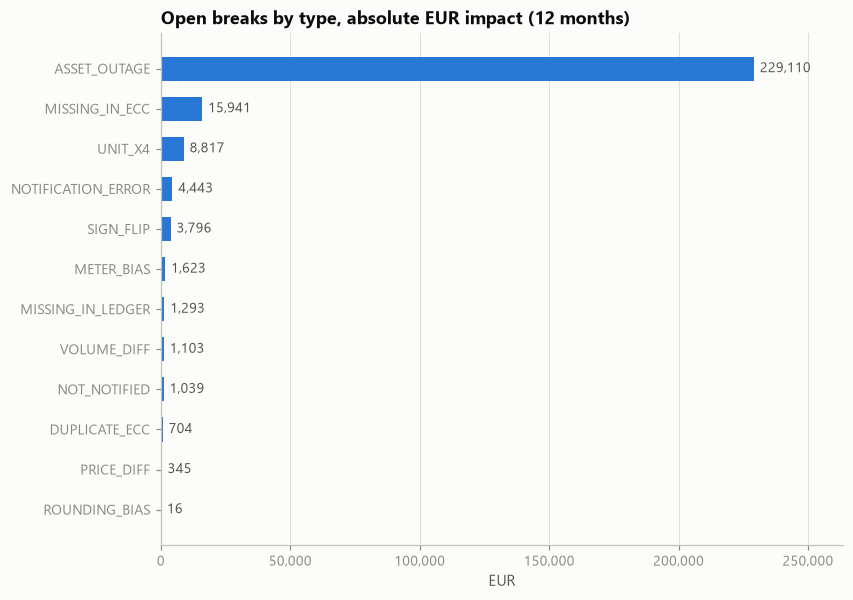

In [13]:
x4 = recon.reconcile_four_way(rec, ops.fahrplan, ops.meter, ops.rebap)
display(x4["status"].value_counts().to_frame("intervals"))
print("Systematic meter deviation (every single interval is inside tolerance):")
display(x4.attrs["meter_bias"].round(3))
reg4 = recon.breaks_four_way(x4)
s4 = reg4.groupby(["type", "owner"]).agg(breaks=("break_id", "size"), intervals=("n_intervals", "sum"),
                                        eur=("eur_impact", "sum")).reset_index()
display(s4)
both = pd.concat([reg2.assign(scope="2-way"), reg4.assign(scope="4-way")])
by_type = both.groupby("type")["abs_eur"].sum().sort_values(ascending=False)
viz.bars(by_type, "Open breaks by type, absolute EUR impact (12 months)", "EUR", fmt="{:,.0f}")
plt.show()

**Four-way findings.**
- **Unplanned outages.** 88 outage events cost about 123k EUR of imbalance; these sit on the asset side and feed the availability KPI.
- **Process errors.** 3 notification errors and 4 trades that were never notified carry about 5.5k EUR of exposure. Small, but avoidable.
- **Meter bias.** One meter reads about 0.3 % low. No single interval is outside tolerance; it surfaces only as a statistical test per month (12 of 12 months flagged).

**Scorecard against the injected truth.**
- Every injected break type is found with the right classification.
- Outages are caught at 560 of 561 intervals.
- There is one false positive (a single interval flagged as a notification error), reported rather than hidden.

In [14]:
score = recon.scorecard(ops.truth_intervals, rec, x4)
display(score)

,type,injected,unit,caught,recall_%,flagged_wrongly
0,ASSET_OUTAGE,561,interval,560,99.82,0
1,DST_FLAG_MISSING,1,interval,1,100.00,0
2,DUPLICATE_ECC,12,interval,12,100.00,0
3,METER_BIAS,1,asset,1,100.00,0
4,MISSING_IN_ECC,24,interval,24,100.00,0
5,MISSING_IN_LEDGER,6,interval,6,100.00,0
6,NOTIFICATION_ERROR,16,interval,16,100.00,1
7,NOT_NOTIFIED,24,interval,24,100.00,0
8,PRICE_DIFF,18,interval,18,100.00,0
9,ROUNDING_BIAS,1,asset,1,100.00,0


## 5 · Variance analysis: an exact price-volume-mix bridge

Every revenue and cost line is generated from a handful of **drivers**:
- MW online and the reserve share;
- MWh discharged per MW;
- the theoretical spread and the capture rate;
- the reserve price;
- the fee rate, degradation rate, imbalance volume and imbalance price.

The bridge therefore adds up **by construction**, and the control `budget + effects - actual = 0` is asserted, here and again in Excel.

Arbitrage revenue is split the way a trading business needs it:

| Effect | Formula |
|---|---|
| cycles (volume) | `(q_A - q_B) × spread_B` |
| market spread (not controllable) | `q_A × (theo_A - theo_B) × capture_B` |
| capture rate (algorithm quality, controllable) | `q_A × theo_A × (capture_A - capture_B)` |

Costs are split into volume and rate (tariff) effects. The order is fixed and stated, because PVM results depend on it.

Order of effects: volume (MW online) -> mix (arbitrage vs reserve) -> price; arbitrage price effect is split into cycles -> market spread -> capture rate; costs: volume then rate. Same order every month.
control - budget + effects - actual: 0.0 EUR


,step,nature,vs budget (Dec-2025 forecast),vs latest forecast (May-2026),explain
0,Budget net trading revenue,start,"523,132.90","522,458.59",False
1,Volume: MW online (COD timing),timing,0.00,0.00,False
2,Mix: arbitrage vs reserve,controllable,0.00,0.00,False
3,Cycles: MWh per MW,controllable,"5,345.75","9,485.07",False
4,Market spread (theoretical),market,"343,670.85","321,259.80",True
5,Capture rate (algorithm),controllable,"32,468.25","32,474.02",True
6,Reserve capacity price,market,"-29,065.79","-6,385.75",True
7,Fees: activity,driven by volume,-20.81,-36.27,False
8,Fees: tariff,external,-250.62,-206.10,False
9,Degradation: volume,driven by volume,-674.52,"-1,150.21",False


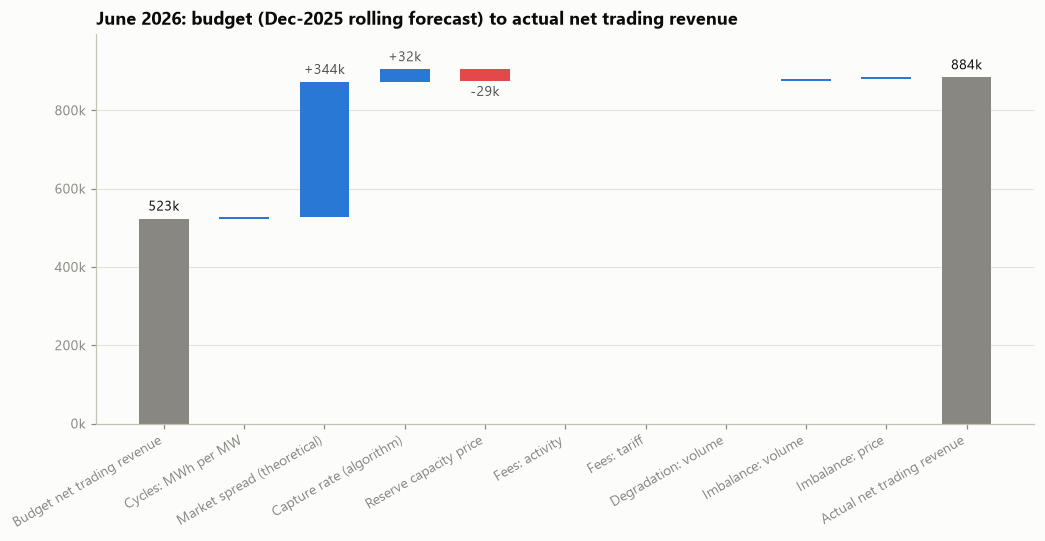

In [15]:
vm = scenarios.variant_monthly(sets, P)
rp = portfolio.reserve_price_path(pd.date_range("2019-01-01", "2027-12-01", freq="MS"))
bt = scenarios.backtest(vm, pm, rp, "2024-12-31", "2026-09-01")
M = pd.Timestamp("2026-06-01")
op_assets = [a for a in ASSETS if a.cod_actual]

def bridge_for(month, origin):
    tab = bt[(bt["as_of"] == pd.Timestamp(origin)) & (bt["month"] == month)]
    parts, pairs = {}, {}
    for a in op_assets:
        b = tab[tab["asset_id"] == a.asset_id]["drivers"].iloc[0]
        row = pm[(pm["month"] == month) & (pm["asset_id"] == a.asset_id)]
        # not yet online (COD later than forecast): zero MW, unit drivers as budgeted -> pure COD-timing effect
        act = portfolio.drivers_row(row.iloc[0]) if len(row) else variance.Drivers(**{**vars(b), "mw": 0.0})
        parts[a.asset_id] = variance.bridge(b, act)
        pairs[a.asset_id] = (b, act)
    return variance.sum_bridges(list(parts.values())), parts, pairs

br_budget, parts_budget, pairs_budget = bridge_for(M, "2025-12-31")
br_latest, _, _ = bridge_for(M, "2026-05-31")
print(variance.ORDER_NOTE)
print("control - budget + effects - actual:", round(br_budget.attrs["check_diff"], 6), "EUR")
tab = br_budget[["step", "nature", "eur"]].rename(columns={"eur": "vs budget (Dec-2025 forecast)"})
tab["vs latest forecast (May-2026)"] = br_latest["eur"].to_numpy()
tab = variance.flag_material(tab.rename(columns={"vs budget (Dec-2025 forecast)": "eur"}), br_budget["eur"].iloc[0]) \
    .rename(columns={"eur": "vs budget (Dec-2025 forecast)"})
display(tab)
viz.waterfall(br_budget, "June 2026: budget (Dec-2025 rolling forecast) to actual net trading revenue")
plt.show()

**June 2026.**
- **Overall.** Actual net trading revenue was 884k EUR against a budget of 523k (the December rolling forecast).
- **Market spread.** +344k, not controllable. Almost the same gap remains against the latest (May) forecast, so a stale budget is not the cause.
- **Capture rate.** +32k, controllable: the algorithm extracted more of the theoretical spread than planned.
- **Reserve price.** -29k (saturation).
- **Tariff effect.** The new exchange tariff shows up as a small, separate tariff effect.
- **Materiality.** Three steps exceed both thresholds (5 % and 25k EUR) and need a written explanation.

In [16]:
rows = []
for origin in sorted(bt["as_of"].unique()):
    month = pd.Timestamp(origin) + pd.Timedelta(days=1)
    if month > pd.Timestamp("2026-09-01"):
        continue
    br_, _, _ = bridge_for(month, origin)
    rows.append(br_.set_index("step")["eur"].rename(month))
att = pd.DataFrame(rows)
mid = att.columns[1:-1]
summary_att = pd.DataFrame({"sum over months (EUR)": att[mid].sum(), "mean |effect| (EUR)": att[mid].abs().mean(),
                            "months actual > forecast": (att[mid] > 0.5).sum(), "months actual < forecast": (att[mid] < -0.5).sum()})
summary_att["share of total |error|"] = summary_att["mean |effect| (EUR)"] / summary_att["mean |effect| (EUR)"].sum()
print(f"One-month-ahead forecast errors, {len(att)} months, decomposed with the same bridge:")
display(summary_att.sort_values("mean |effect| (EUR)", ascending=False))

One-month-ahead forecast errors, 21 months, decomposed with the same bridge:


,sum over months (EUR),mean |effect| (EUR),months actual > forecast,months actual < forecast,share of total |error|
step,,,,,
Market spread (theoretical),"1,489,513.01","144,823.38",14,7,0.62
Capture rate (algorithm),"118,260.52","31,748.98",12,9,0.14
Cycles: MWh per MW,"-81,347.69","24,056.76",10,11,0.10
Imbalance: price,"-50,377.72","12,286.13",9,12,0.05
Reserve capacity price,"-133,033.10","11,406.06",5,16,0.05
Imbalance: volume,-478.83,"3,871.73",13,8,0.02
Degradation: volume,"7,596.27","2,862.40",10,11,0.01
Volume: MW online (COD timing),"-27,479.90","2,410.56",1,3,0.01
Fees: activity,244.90,89.24,10,11,0.00


**Forecast error attribution.** Running the same bridge over all 21 one-month-ahead forecasts shows *why* the rolling forecast misses:
- **Market spread.** 62 % of the average absolute error, mostly in one direction (actual above forecast in 14 of 21 months).
- **Reserve price.** Actual fell below forecast in **16 of 21 months**. The flat "last three months" assumption is systematically wrong in a saturating market. Action: put a downward trend into the reserve-price assumption.

## 6 · Rolling forecast, scenarios and probabilistic view

At every month-end the next 12 months are re-forecast from trailing data:
- **Spread and cycles:** trailing-12-month level × seasonal index.
- **Capture, fees, imbalance:** trailing 12 months.
- **Reserve price:** last three months.
- **COD:** for assets not yet online, the planned COD is probability-weighted with typical delays (delays are the rule, not the exception).

The backtest compares every forecast with what actually happened, by horizon.

,n,MAPE %,bias % (forecast-actual)
h,,,
1,21,32.70,-10.20
2,20,34.90,-11.20
3,19,37.10,-12.40
4,18,38.70,-12.70
5,17,39.60,-12.40
6,16,40.40,-11.90
7,15,40.60,-10.80
8,14,41.10,-11.00
9,13,41.70,-11.00


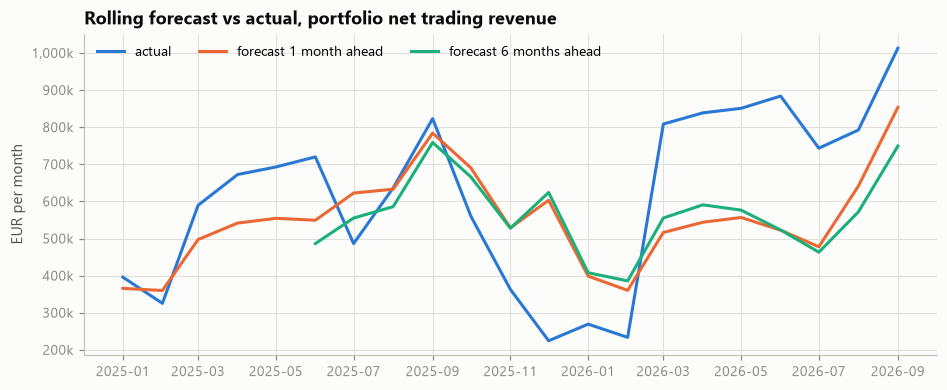

In [17]:
acc = scenarios.accuracy_by_horizon(bt)
display(acc)
pt = bt.groupby(["as_of", "month", "h"])[["Net trading revenue", "actual"]].sum().reset_index()
act_m = pt.groupby("month")["actual"].first()
h1 = pt[pt["h"] == 1].set_index("month")["Net trading revenue"]
h6 = pt[pt["h"] == 6].set_index("month")["Net trading revenue"]
comp = pd.DataFrame({"actual": act_m, "forecast 1 month ahead": h1, "forecast 6 months ahead": h6}).dropna(subset=["forecast 1 month ahead"])
viz.lines(comp, list(comp.columns), "Rolling forecast vs actual, portfolio net trading revenue", "EUR per month", scale="k")
plt.show()

**Backtest.**
- **Accuracy.** Monthly MAPE grows from 33 % one month ahead to 45 % twelve months ahead.
- **Bias.** It is consistently negative (-10 % to -16 %): in a market whose spreads widened through 2026, a trailing method lags.
- **What it means.** MAPE is far larger than |bias|, so most of the error is genuine month-to-month volatility, but the persistent part is systematic and fixable. Monthly trading revenue cannot be forecast tightly, which is exactly why the scenario and probability views below matter more than the point forecast.

In [18]:
# model choice is tested, not assumed: seasonal index from the mean vs the median of yearly profiles
res = {}
for agg in ["mean", "median"]:
    scenarios.SEASONAL_AGG = agg
    a_ = scenarios.accuracy_by_horizon(scenarios.backtest(vm, pm, rp, "2024-12-31", "2026-09-01"))
    res[f"seasonality = {agg}"] = a_.loc[[1, 3, 6, 12], "MAPE %"].rename(lambda h: f"MAPE h={h}")
scenarios.SEASONAL_AGG = "median"
display(pd.DataFrame(res).T)

h,MAPE h=1,MAPE h=3,MAPE h=6,MAPE h=12
seasonality = mean,34.00,39.70,42.40,46.20
seasonality = median,32.70,37.10,40.40,44.50


**A model choice tested, not assumed.** The seasonal index was first built from the *mean* of yearly profiles. The 2021-22 crisis winters distort that mean, so a *median* index was tested. It improves every horizon (e.g. 34.0 % → 32.7 % one month ahead) and is used throughout. The remaining error is a level shift, not seasonality.

In [19]:
AS_OF = "2026-09-30"
inp = scenarios.build_inputs(vm, pm, rp, AS_OF)
ratio = scenarios.spread_ratio_distribution(vm)
print(f"Spread ratio (next 12m / trailing 12m), n={len(ratio)} monthly origins since 2019, centred on its median "
      f"(raw median {ratio.attrs['raw_median']:.2f}):")
display(ratio.quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]).to_frame("ratio").T.round(2))
sc_sets = scenarios.scenario_sets(ratio)
display(pd.DataFrame({k: vars(v) for k, v in sc_sets.items()}).T)
scen = scenarios.run_scenarios(inp, sc_sets)
display(scen.round(0))

Spread ratio (next 12m / trailing 12m), n=71 monthly origins since 2019, centred on its median (raw median 1.18):


,0.05,0.10,0.25,0.50,0.75,0.90,0.95
ratio,0.49,0.52,0.89,1.00,1.22,2.09,2.32


,theo_mult,cap_add,q_mult,res_mult,fee_mult,imb_rate_mult,cod_mode,cod_delay_m,share_add
Stress,0.52,-0.06,0.95,0.55,1.00,1.40,delay,9,0.00
Downside,0.89,-0.03,0.97,0.70,1.00,1.20,delay,6,0.00
Base,1.00,0.00,1.00,1.00,1.00,1.00,weighted,0,0.00
Upside,1.22,0.02,1.00,1.10,1.00,0.90,plan,0,0.00


,layer1_net,company_revenue,floor_topup,cost_to_serve,direct_costs,joint_costs,company_ebitda
Stress,"2,947,749.00","-393,545.00","816,687.00","126,000.00","102,000.00","552,000.00","-1,173,545.00"
Downside,"6,028,898.00","866,711.00",0.00,"128,500.00","102,000.00","552,000.00","84,211.00"
Base,"7,952,878.00","1,145,639.00",0.00,"136,125.00","102,000.00","552,000.00","355,514.00"
Upside,"10,513,152.00","1,568,436.00",0.00,"143,500.00","102,000.00","552,000.00","770,936.00"


**Scenarios are consistent worlds, not single-variable tweaks.** The spread level comes from history: for every month since 2019, the ratio of next-12-month to trailing-12-month spread. This distribution is centred on its median so the base keeps the current level. Downside and upside use P25 / P75, stress uses P10. The other levers move in the same direction:
- capture rate;
- reserve price (saturation);
- imbalance price;
- COD delay of the pre-COD asset.

**What the stress case shows.**
- **Asset revenue.** Layer 1 falls to 2.9M EUR (base 8.0M).
- **Floor payout.** The floor in the C2 contract pays out about 0.82M EUR. A floor is a *put option written by the company*: invisible in good years, decisive in bad ones.
- **Company result.** Company revenue turns negative and EBITDA reaches -1.17M EUR (base +0.36M).

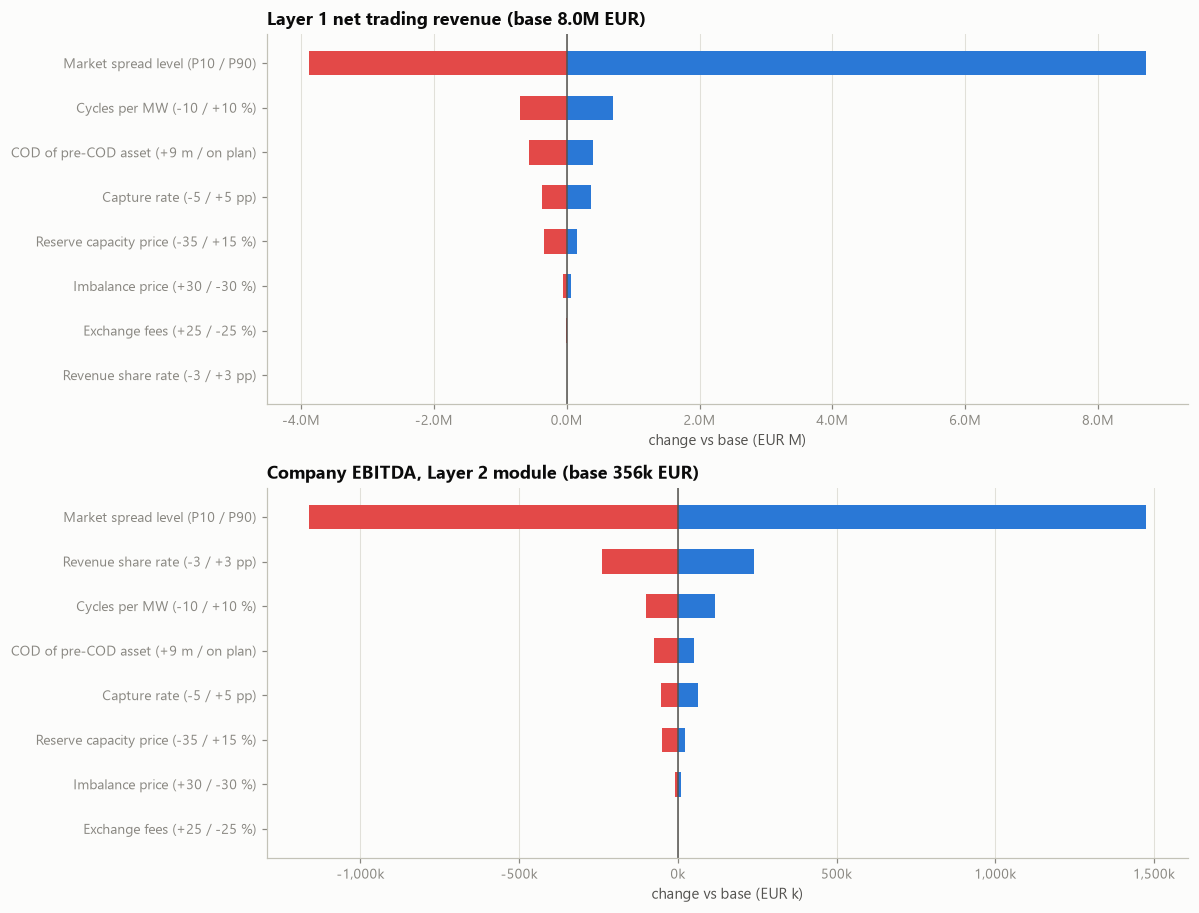

Layer 1                            company EBITDA                          
                                                low         high         range            low         high        range
driver                                                                                                                 
Market spread level (P10 / P90)       -3,883,320.00 8,724,147.00 12,607,467.00  -1,162,757.00 1,475,391.00 2,638,148.00
Cycles per MW (-10 / +10 %)             -696,707.00   696,707.00  1,393,414.00    -100,537.00   117,826.00   218,362.00
COD of pre-COD asset (+9 m / on plan)   -573,749.00   392,717.00    966,466.00     -75,937.00    51,533.00   127,470.00
Capture rate (-5 / +5 pp)               -370,330.00   370,330.00    740,659.00     -53,495.00    62,649.00   116,144.00
Reserve capacity price (-35 / +15 %)    -345,033.00   147,871.00    492,905.00     -49,415.00    23,907.00    73,322.00
Imbalance price (+30 / -30 %)            -59,253.00    59,253.00    118,507.00      -8,610.00    10,020.00    18,630.00
Exchange fees (+25 / -25 %)               -6,838.00     6,838.00     13,676.00      -1,062.00     1,156.00     2,218.00
Revenue share rate (-3 / +3 pp)                0.00         0.00          0.00    -238,586.00   238,586.00   477,173.00

In [20]:
tor_l1 = scenarios.tornado(inp, ratio, "layer1_net")
tor_co = scenarios.tornado(inp, ratio, "company_ebitda")
fig, axs = plt.subplots(2, 1, figsize=(11, 8.4))  # each panel sorted by its own range, so each keeps its own labels
viz.tornado(tor_l1, f"Layer 1 net trading revenue (base {tor_l1.attrs['base'] / 1e6:,.1f}M EUR)", scale="M", ax=axs[0])
viz.tornado(tor_co, f"Company EBITDA, Layer 2 module (base {tor_co.attrs['base'] / 1e3:,.0f}k EUR)", scale="k", ax=axs[1])
plt.tight_layout(); plt.show()
display(pd.concat({"Layer 1": tor_l1.set_index("driver"), "company EBITDA": tor_co.set_index("driver")}, axis=1).round(0))

**Tornado (one driver at a time, P10 / P90 or ± as labelled).**
- **Market spread** dominates both views.
- **Revenue-share rate** comes second for company EBITDA (±0.24M EUR). It is a commercial lever, not a market one.
- **Cycles per MW** come next (±0.1-0.12M EUR of EBITDA).
- **COD timing and capture rate** follow, each worth about 0.1M EUR of EBITDA swing. COD timing of the pre-COD asset alone moves Layer 1 by about 1M EUR.
- **Exchange fees** are immaterial.

,mean,P50,P90 (empirical),P90 (normal approx),P99 (empirical),P99 (normal approx),skewness
layer1_net,"9,227,871.67","8,017,195.56","4,156,769.40","3,466,484.41","3,281,604.28","-1,229,927.33",1.25
company_ebitda,"492,821.68","369,184.32","-771,947.13","-624,459.31","-1,103,680.31","-1,535,214.18",0.57


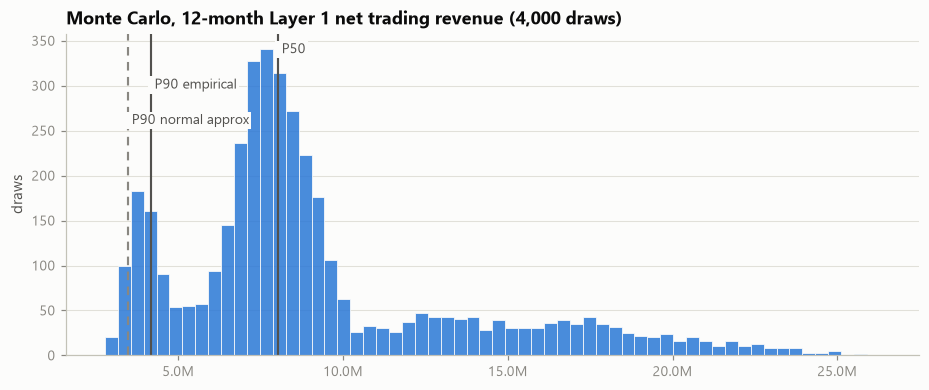

share of draws in which the C2 floor pays out: 19.6%; mean top-up when it does: 513,728 EUR


In [21]:
mc = scenarios.monte_carlo(inp, ratio, n=config.MC_DRAWS)
pct = pd.DataFrame({c: scenarios.percentiles(mc[c]) for c in ["layer1_net", "company_ebitda"]}).T
display(pct.round(2))
p = scenarios.percentiles(mc["layer1_net"])
viz.histogram(mc["layer1_net"], {"P50": p["P50"], "P90 empirical": p["P90 (empirical)"], "P90 normal approx": p["P90 (normal approx)"]},
              f"Monte Carlo, 12-month Layer 1 net trading revenue ({len(mc):,} draws)", scale="M")
plt.show()
print(f"share of draws in which the C2 floor pays out: {(mc['floor_topup'] > 0).mean():.1%}; "
      f"mean top-up when it does: {eur(mc.loc[mc['floor_topup'] > 0, 'floor_topup'].mean())}")

**Monte Carlo (4,000 draws)** combines empirical spread ratios, capture noise, reserve and imbalance price multipliers and a COD-delay distribution.

| | Empirical | Normal approximation |
|---|---|---|
| P50 | 8.0M (≈ base) | |
| P90 (exceeded with 90 % probability) | 4.2M | 3.5M |
| P99 | +3.3M | -1.2M |

The distribution is **right-skewed** (skewness 1.25). The normal approximation is too pessimistic at P90 and absurd at P99, so percentiles should be read from the simulation, not from mean minus k·sigma. The floor pays out in about 20 % of draws, with an average top-up of about 0.5M EUR when it does.

## 7 · Product and customer profitability (company view)

**Products.** Each asset's net revenue is split by market product (day-ahead, intraday, reserve capacity). Company revenue (Layer-2 module) is attributed to products in proportion to their contribution.
- **CM1** = company revenue − product-specific direct costs (data, order-book feeds, prequalification).
- **Joint costs** (trading team, data & IT, balance group) are then allocated twice: by revenue and by activity (trader hours, messages, MWh through the balance group).

**Customers.** Cost-to-serve is shown per customer and per MW.

,revenue,contribution_l1,company_revenue,direct_costs,CM1,joint_by_revenue,joint_by_activity,net_by_revenue_key,net_by_activity_key
product,,,,,,,,,
Day-ahead,"6,054,337.00","5,114,042.00","738,762.00","12,000.00","726,762.00","372,642.00","110,400.00","354,120.00","616,362.00"
Intraday,"1,520,073.00","1,474,047.00","213,346.00","60,000.00","153,346.00","107,615.00","346,800.00","45,731.00","-193,454.00"
Reserve capacity,"993,370.00","993,370.00","142,232.00","30,000.00","112,232.00","71,744.00","94,800.00","40,488.00","17,432.00"


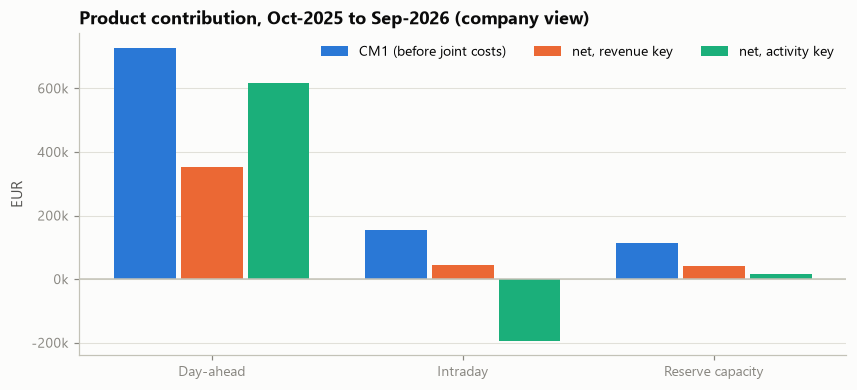

In [22]:
PNL_START, PNL_END = "2025-10-01", "2026-09-01"
prod, cust, attr = profitability.product_pnl(pm, PNL_START, PNL_END)
cols = ["revenue", "contribution_l1", "company_revenue", "direct_costs", "CM1", "joint_by_revenue", "joint_by_activity",
        "net_by_revenue_key", "net_by_activity_key"]
display(prod[cols].round(0))
viz.grouped_bars(prod[["CM1", "net_by_revenue_key", "net_by_activity_key"]].rename(columns={
    "CM1": "CM1 (before joint costs)", "net_by_revenue_key": "net, revenue key", "net_by_activity_key": "net, activity key"}),
    ["CM1 (before joint costs)", "net, revenue key", "net, activity key"],
    "Product contribution, Oct-2025 to Sep-2026 (company view)", "EUR")
plt.show()

**The key decides the verdict.**
- **Intraday** earns a positive CM1 of 153k EUR. After joint costs it shows +46k under the revenue key but **-193k under the activity key**, because it consumes about two thirds of trader time.
- **Day-ahead** looks about 1.7 times as good under the activity key (616k) as under the revenue key (354k).

The total is identical in both cases. Allocation moves profit between products, it does not create it.

In [23]:
loser = prod["net_by_activity_key"].idxmin()
dt = profitability.drop_test(prod, loser)
print(f"Drop test for '{loser}' (looks loss-making under the activity key):")
display(dt.round(0))
print(f"company result before: {eur(dt.attrs['company_result_before'])} | after dropping: {eur(dt.attrs['company_result_after'])} "
      f"| change = -CM1 of the dropped product: {eur(-dt.attrs['dropped_cm1'])}")
display(cust.round(0))

Drop test for 'Intraday' (looks loss-making under the activity key):


,net before drop,net after drop
product,,
Day-ahead,"616,362.00","429,779.00"
Reserve capacity,"17,432.00","-142,785.00"


company result before: 440,339 EUR | after dropping: 286,994 EUR | change = -CM1 of the dropped product: -153,346 EUR


,customer,asset_id,type,MW,contract,layer1_net,company_revenue,of_which_floor_topup,cost_to_serve,contribution_after_cts,company_rev_per_MW,cts_per_MW
0,C1,BESS-A,stand-alone,60.00,net_fixed,"4,601,676.00","690,251.00",-0.00,"29,979.00","660,272.00","11,504.00",500.00
1,C2,BESS-B,co-located,30.00,tiered_floor,"2,482,965.00","304,724.00",-0.00,"59,959.00","244,765.00","10,157.00","1,999.00"
2,C3,BESS-C,stand-alone,10.00,fixed_min_fee,"496,818.00","99,364.00",-0.00,"35,975.00","63,388.00","9,936.00","3,598.00"


**Death-spiral test.** Dropping the "loss-making" intraday product:
- **Company result.** It falls from 440k to 287k EUR, exactly the lost CM1.
- **Remaining products.** The joint costs stay and move to the other products, so reserve capacity now looks loss-making too.

Drop decisions belong on *avoidable* costs. The better levers are automation (fewer trader hours per intraday MWh) and product-specific pricing.

**Cost to serve.** It is 3.6k EUR per MW for the small 1-hour asset vs 0.5k for the large stand-alone one. That argues for the minimum monthly fee in that contract.

## 8 · Excel deliverable with built-in checks

The workbook (`outputs/flex_controlling_case.xlsx`) follows the controlling primer's rules:

**Sheets**
- **Inputs** on their own sheet, editable cells coloured.
- **Live formulas, not pasted numbers.** The bridge and the product P&L recalculate in Excel; the allocation key is a drop-down.
- **Break register** with a status drop-down.
- **Change log.**

**Checks:** a `Checks` sheet with 12 tests and one master flag:
- cross-foots;
- sign convention;
- DST interval counts;
- full allocation;
- bridge residual;
- reconciliation totals.

I verified the file by recalculating it in Excel: all 12 checks return OK. A deliberate negative test (one cost entered with the wrong sign, one allocation key broken) flips the master flag to ERROR.

In [24]:
rd_l = ops.ledger.assign(local_date=ops.ledger["ts_utc"].dt.tz_convert(TZ).dt.strftime("%Y-%m-%d")) \
    .groupby(["asset_id", "local_date"]).agg(ledger_rows=("net_mwh", "size"), ledger_mwh=("net_mwh", "sum"), ledger_eur=("amount_eur", "sum"))
rd_e = ep.assign(local_date=ep["ts_utc"].dt.tz_convert(TZ).dt.strftime("%Y-%m-%d"), net=ep["sell_mwh"] - ep["buy_mwh"]) \
    .groupby(["asset_id", "local_date"]).agg(ecc_rows=("net", "size"), ecc_mwh=("net", "sum"), ecc_eur=("amount_eur", "sum"))
recon_daily = rd_l.join(rd_e, how="outer").fillna(0).reset_index()[
    ["asset_id", "local_date", "ledger_rows", "ecc_rows", "ledger_mwh", "ecc_mwh", "ledger_eur", "ecc_eur"]]
reg_cols = ["break_id", "scope", "asset_id", "local_date", "type", "n_intervals", "mwh_diff", "eur_impact", "severity",
            "owner", "root_cause", "next_step", "age_days", "status"]
register = pd.concat([reg2.assign(scope="2-way", break_id="R2-" + reg2["break_id"]),
                      reg4.assign(scope="4-way", break_id="R4-" + reg4["break_id"])])[reg_cols]
register["severity"] = register["severity"].astype(str)
R = {
    "assumptions": config.assumptions_table(), "pm": pm,
    "bridge_label": "June 2026, budget = Dec-2025 rolling forecast", "bridge_order_note": variance.ORDER_NOTE,
    "bridge_parts": pairs_budget, "bridge_steps": {k: v for k, v in parts_budget.items()},
    "interval_check": ic, "recon_daily": recon_daily, "register": register,
    "accuracy": acc, "scenarios": scen, "tornado_l1": tor_l1, "tornado_co": tor_co, "mc_pct": pct,
    "prod": prod, "cust": cust, "pnl_window": "Oct-2025 to Sep-2026", "pnl_months": prod.attrs["months"],
    "pnl_start": pd.Timestamp(PNL_START), "pnl_end": pd.Timestamp(PNL_END),
    "joint_costs": config.JOINT_COSTS_EUR_MONTH, "alloc_activity": config.ALLOC_ACTIVITY,
    "direct_costs": config.DIRECT_COSTS_EUR_MONTH,
    "change_log": pd.DataFrame([
        {"date": pd.Timestamp("2026-10-20"), "version": "1.0", "change": "First version: data audit, reconciliation, bridge, scenarios, product P&L."},
    ]),
}
xlsx = OUT / "flex_controlling_case.xlsx"
try:
    info = excel_out.write_workbook(str(xlsx), R)
    print("written:", xlsx.relative_to(ROOT) if xlsx.is_relative_to(ROOT) else xlsx)
    for i, c in enumerate(info["checks"], 1):
        print(f"  check {i:2d}: {c}")
except ImportError as exc:                       # e.g. a fresh environment without xlsxwriter
    print("Excel export skipped:", exc, "-> pip install xlsxwriter")

written: outputs\flex_controlling_case.xlsx
  check  1: Round-trip efficiency is plausible (0.80-0.95)
  check  2: Monthly net revenue = sum of its lines (every row)
  check  3: Cost lines are entered as positive amounts (sign convention)
  check  4: Bridge: budget + effects = actual (no unexplained residual)
  check  5: Bridge: asset columns cross-foot to the portfolio column
  check  6: Price series complete on every local day incl. DST days
  check  7: Intervals in the price file = intervals implied by the calendar (cross-foot)
  check  8: Recon: daily differences cross-foot to total statement - total ledger
  check  9: Activity keys sum to 100 % for every cost pool
  check 10: Joint costs fully allocated - revenue key
  check 11: Joint costs fully allocated - activity key
  check 12: Product L1 contributions = portfolio net revenue in the window (Monthly_Actuals)


## 9 · Summary for the CFO

In [25]:
kpi = pd.Series({
    "price intervals audited": f"{audit['intervals']:,}",
    "forecast MAE ML vs naive (EUR/MWh)": f"{fm.loc['gradient boosting (walk-forward)', 'MAE']:.1f} vs {fm.loc['naive (D-1 / D-7 weekday rule)', 'MAE']:.1f}",
    "capture rate ML vs naive (2025)": f"{cap.loc[2025, 'capture ML %']:.1f}% vs {cap.loc[2025, 'capture naive %']:.1f}%",
    "intervals reconciled (12 m)": f"{summ['intervals_compared']:,}",
    "within tolerance": f"{summ['within_tolerance_%']:.1f}%",
    "injected break types caught": f"{(score['recall_%'] == 100).sum()} of {len(score)} at 100% recall",
    "rolling forecast bias (1 month ahead)": f"{acc.loc[1, 'bias % (forecast-actual)']:.1f}%",
    "12m Layer 1 net, base / P90 empirical": f"{scen.loc['Base', 'layer1_net'] / 1e6:.1f}M / {pct.loc['layer1_net', 'P90 (empirical)'] / 1e6:.1f}M EUR",
    "company EBITDA stress / base / upside": " / ".join(f"{scen.loc[k, 'company_ebitda'] / 1e3:,.0f}k" for k in ["Stress", "Base", "Upside"]),
}, name="value")
display(kpi.to_frame())

,value
price intervals audited,"273,500"
forecast MAE ML vs naive (EUR/MWh),24.2 vs 29.6
capture rate ML vs naive (2025),85.9% vs 81.8%
intervals reconciled (12 m),"23,274"
within tolerance,99.3%
injected break types caught,12 of 13 at 100% recall
rolling forecast bias (1 month ahead),-10.2%
"12m Layer 1 net, base / P90 empirical",8.0M / 4.2M EUR
company EBITDA stress / base / upside,"-1,174k / 356k / 771k"


## 10 · Limitations and next steps

**Limitations**
- **Synthetic records.** The operational records are synthetic. The engine is proven on known breaks, not yet on real statements.
- **Modelled markets.** Intraday value, reserve capacity prices and reBAP are modelled. Replacing them with real data would sharpen sections 3, 5 and 6 most: published imbalance prices, intraday indices (ID3) and reserve auction results.
- **Forecast inputs.** The price forecast has no day-ahead wind / solar forecasts; adding them is the obvious next gain.
- **Contracts.** Contract terms (Layer 2) are illustrative. The module is deliberately separable.

**Operational next step:** run the reconciliation daily (parameterised notebook, e.g. Papermill) instead of at month-end, with the break register as a shared, ageing list.